# PRCP-1005 — Forest Cover Type Prediction

**Goal:** predict which of seven forest cover types grows on a 30 m × 30 m cell of the Roosevelt National Forest
(northern Colorado), using terrain, distance, hillshade, wilderness-area and soil-type data.

| Deliverable | Where in this notebook |
|---|---|
| Task 1 — Data analysis report | Sections 2–7 |
| Task 2 — Predictive model | Sections 8–13 |
| Model comparison report | Section 14 |
| Report on challenges faced | Section 15 |

Data: `data/train.csv` from the project zip (15,120 labelled rows, 56 columns).

**To run:**
1. `pip install -r requirements.txt`
2. Restart the kernel and run all cells.

A full run takes about 20 minutes on a 24-core machine; the hyper-parameter search in section 11 is most of it.
Results are reproducible: the random seed is fixed to 42.

## 1. Setup

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_score,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 70)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

DATA_PATH = Path("data/train.csv")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

# Task 1 — Data Analysis Report

## 2. Load the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 15,120   Columns: 56


,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


In [3]:
TARGET = "Cover_Type"
NUM = ["Elevation", "Aspect", "Slope",
       "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
       "Horizontal_Distance_To_Roadways",
       "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
       "Horizontal_Distance_To_Fire_Points"]
WILD = [c for c in df.columns if c.startswith("Wilderness_Area")]
SOIL = [c for c in df.columns if c.startswith("Soil_Type")]

# Cover-type names from the UCI Covertype documentation (the project brief lists only the codes).
COVER_NAMES = {1: "Spruce/Fir", 2: "Lodgepole Pine", 3: "Ponderosa Pine", 4: "Cottonwood/Willow",
               5: "Aspen", 6: "Douglas-fir", 7: "Krummholz"}
WILD_NAMES = {1: "Rawah", 2: "Neota", 3: "Comanche Peak", 4: "Cache la Poudre"}

print(f"Numeric features: {len(NUM)} | Wilderness columns: {len(WILD)} | Soil columns: {len(SOIL)} | + Id + target")

Numeric features: 10 | Wilderness columns: 4 | Soil columns: 40 | + Id + target


## 3. Data quality checks

In [4]:
quality = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Missing values (total)": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Duplicate rows ignoring Id": int(df.drop(columns="Id").duplicated().sum()),
    "Id unique": bool(df["Id"].is_unique),
    "Non-integer columns": int((df.dtypes != "int64").sum()),
}, name="value").to_frame()
quality

,value
Rows,15120
Columns,56
Missing values (total),0
Duplicate rows,0
Duplicate rows ignoring Id,0
Id unique,True
Non-integer columns,0


In [5]:
df[NUM].describe().T

,count,mean,std,min,25%,50%,75%,max
Elevation,15120.0000,2749.3226,417.6782,1863.0000,2376.0000,2752.0000,3104.0000,3849.0000
Aspect,15120.0000,156.6767,110.0858,0.0000,65.0000,126.0000,261.0000,360.0000
Slope,15120.0000,16.5016,8.4539,0.0000,10.0000,15.0000,22.0000,52.0000
Horizontal_Distance_To_Hydrology,15120.0000,227.1957,210.0753,0.0000,67.0000,180.0000,330.0000,1343.0000
Vertical_Distance_To_Hydrology,15120.0000,51.0765,61.2394,-146.0000,5.0000,32.0000,79.0000,554.0000
Horizontal_Distance_To_Roadways,15120.0000,1714.0232,1325.0664,0.0000,764.0000,1316.0000,2270.0000,6890.0000
Hillshade_9am,15120.0000,212.7043,30.5613,0.0000,196.0000,220.0000,235.0000,254.0000
Hillshade_Noon,15120.0000,218.9656,22.8020,99.0000,207.0000,223.0000,235.0000,254.0000
Hillshade_3pm,15120.0000,135.0920,45.8952,0.0000,106.0000,138.0000,167.0000,248.0000
Horizontal_Distance_To_Fire_Points,15120.0000,1511.1473,1099.9365,0.0000,730.0000,1256.0000,1988.2500,6993.0000


**Data quality findings**

- 15,120 rows × 56 columns, all integers. **No missing values and no duplicate rows**, even ignoring `Id`.
- `Id` is just a row number, so it carries no information and is dropped before modelling.
- The numeric features are on very different scales: elevation runs from about 1,860 to 3,850 m,
  slope from 0 to 52°, and the distances go up to about 7,000 m. That matters for distance- and
  gradient-based models (KNN, SVM, logistic regression) but not for tree models.
- `Vertical_Distance_To_Hydrology` goes **negative** (minimum −146). That is valid: the cell sits *below* its nearest water.

## 4. Target variable

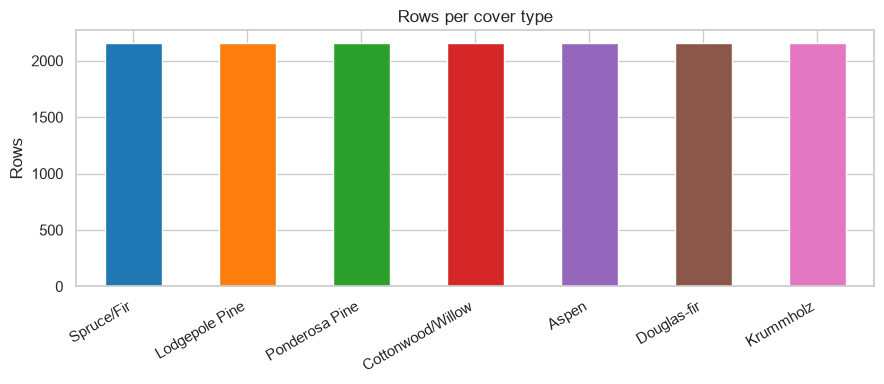

,rows,share
Cover_Type,,
1,2160,0.1429
2,2160,0.1429
3,2160,0.1429
4,2160,0.1429
5,2160,0.1429
6,2160,0.1429
7,2160,0.1429


In [6]:
counts = df[TARGET].value_counts().sort_index()
ax = counts.rename(index=COVER_NAMES).plot.bar(color=sns.color_palette("tab10", 7), figsize=(9, 4))
ax.set(title="Rows per cover type", xlabel="", ylabel="Rows")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
counts.to_frame("rows").assign(share=lambda t: t["rows"] / t["rows"].sum())

**The target is perfectly balanced:** exactly 2,160 rows (1/7, 14.3%) for each of the 7 cover types.
- Plain accuracy is therefore a fair metric, and no resampling or class weights are needed.
- A model that always guesses one class scores only 14.3%. That is the floor every model must beat.
- This balance was clearly *chosen* when the sample was made: in the full forest, Spruce/Fir and Lodgepole Pine
  cover most of the land. Accuracy measured here is accuracy on a balanced mix, not on the real forest.

## 5. Numeric features

### 5.1 Distributions

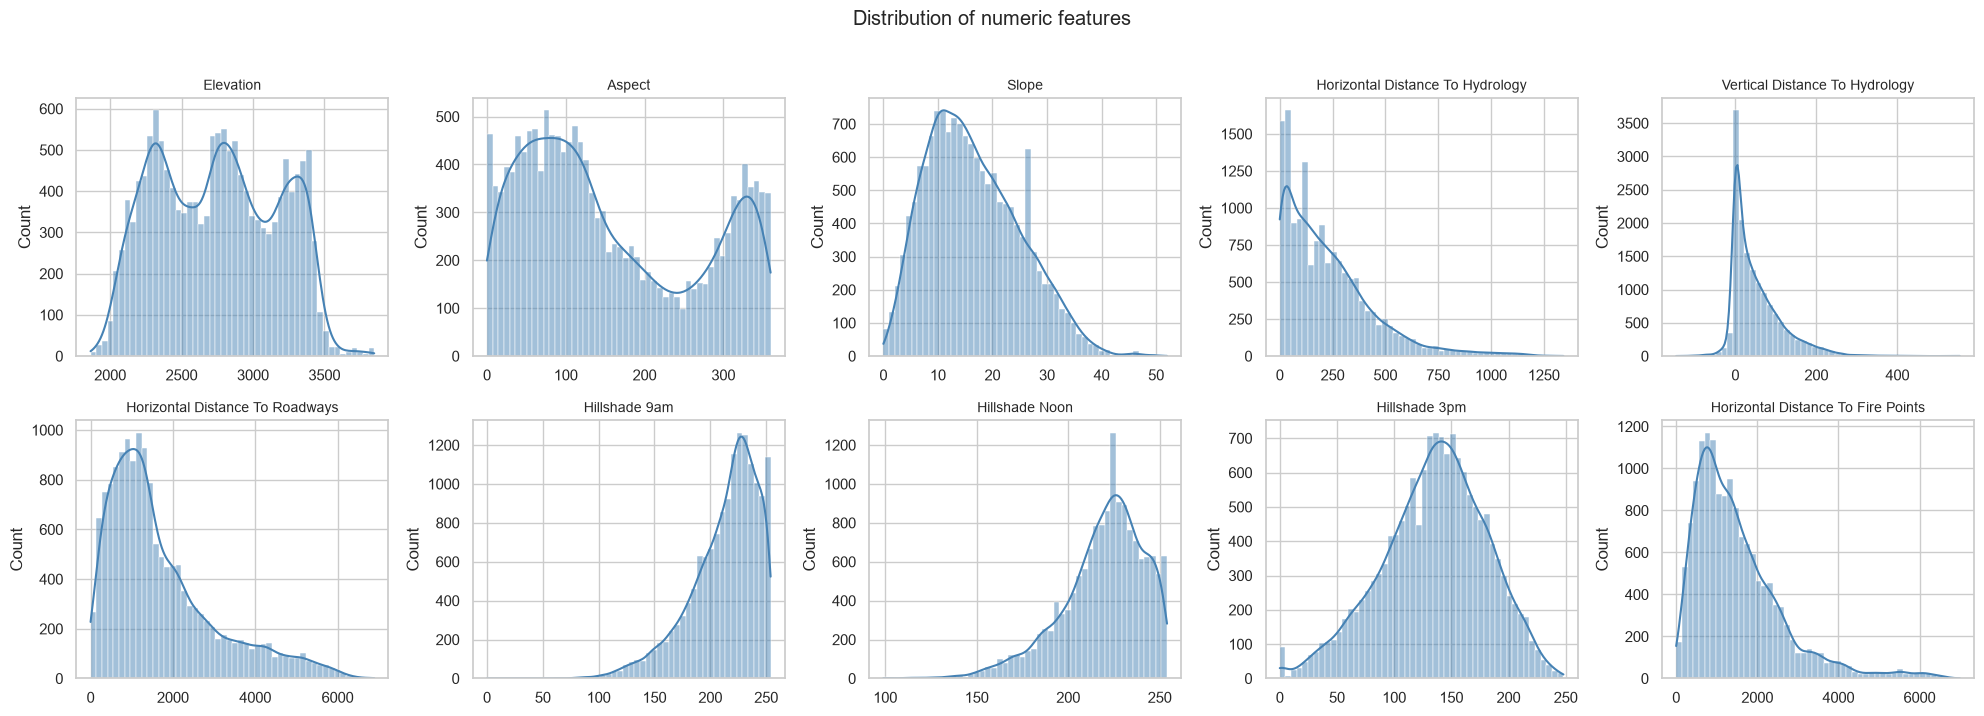

,skewness,kurtosis
Elevation,0.0756,-1.0821
Aspect,0.4509,-1.1502
Slope,0.5237,-0.2383
Horizontal_Distance_To_Hydrology,1.4881,2.8040
Vertical_Distance_To_Hydrology,1.5378,3.4035
Horizontal_Distance_To_Roadways,1.2478,1.0224
Hillshade_9am,-1.0937,1.2188
Hillshade_Noon,-0.9532,1.1535
Hillshade_3pm,-0.3408,-0.0873
Horizontal_Distance_To_Fire_Points,1.6171,3.3854


In [7]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), NUM):
    sns.histplot(df[col], bins=50, kde=True, ax=ax, color="steelblue")
    ax.set_title(col.replace("_", " "), fontsize=10); ax.set_xlabel("")
plt.suptitle("Distribution of numeric features", y=1.02); plt.tight_layout(); plt.show()

df[NUM].agg(["skew", "kurt"]).T.rename(columns={"skew": "skewness", "kurt": "kurtosis"})

### 5.2 Numeric features by cover type

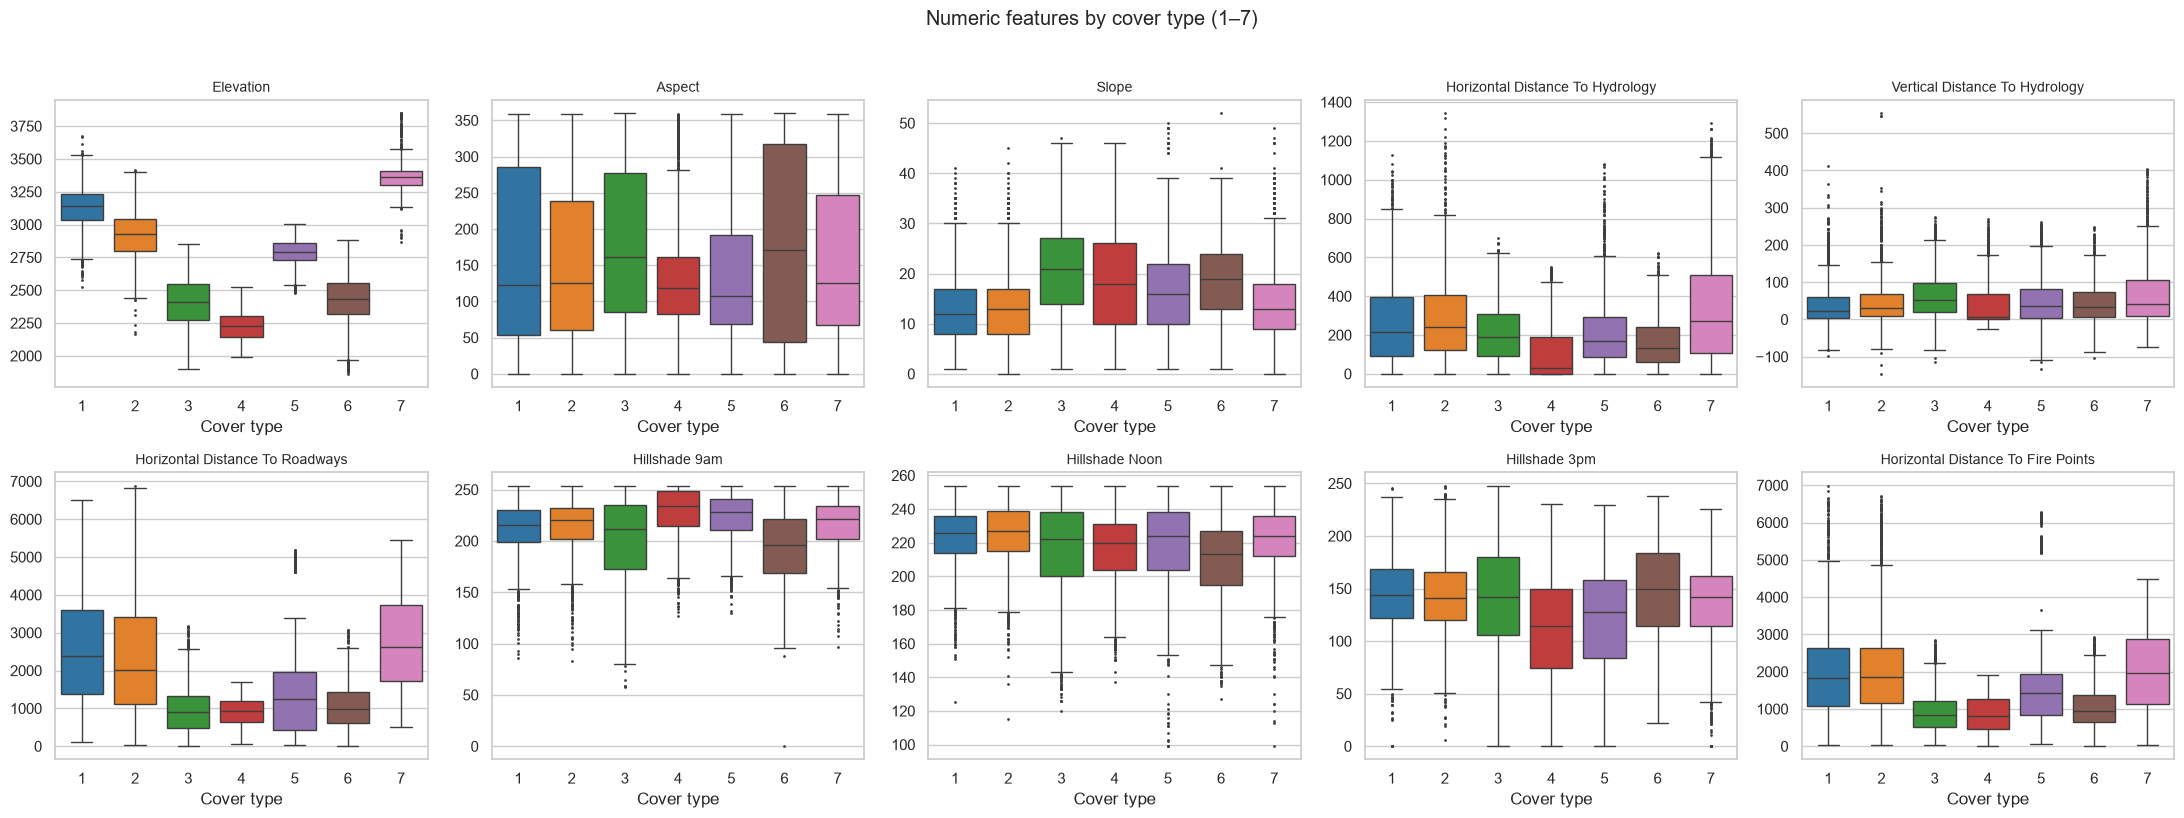

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), NUM):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, hue=TARGET, palette="tab10", legend=False, fliersize=1)
    ax.set_title(col.replace("_", " "), fontsize=10); ax.set_xlabel("Cover type"); ax.set_ylabel("")
plt.suptitle("Numeric features by cover type (1–7)", y=1.02); plt.tight_layout(); plt.show()

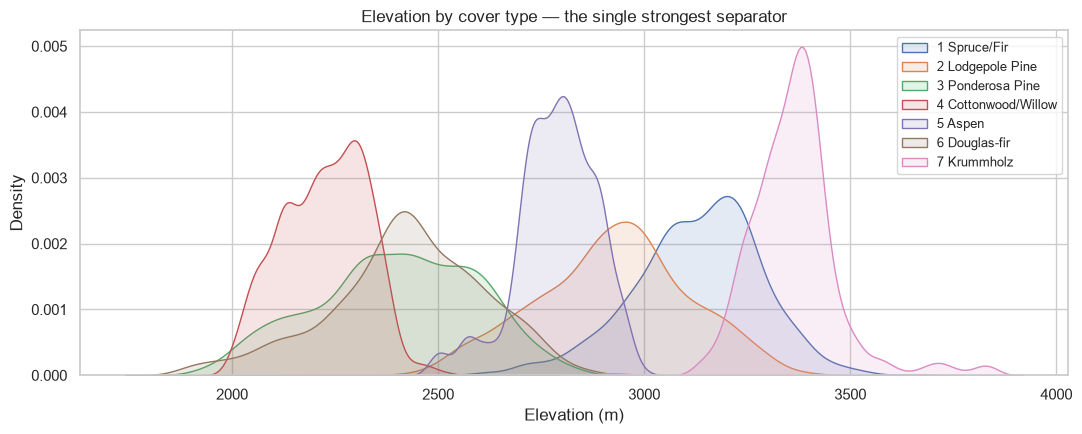

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
Cover_Type,,,,,,,,,,
Spruce/Fir,3144.0000,123.0000,12.0000,218.0000,23.0000,2377.0000,216.0000,226.0000,144.0000,1817.5000
Lodgepole Pine,2931.5000,125.0000,13.0000,242.0000,31.0000,2023.5000,220.0000,227.0000,141.0000,1851.0000
Ponderosa Pine,2409.0000,161.0000,21.0000,190.0000,51.0000,897.0000,212.0000,222.0000,142.0000,828.0000
Cottonwood/Willow,2230.5000,119.0000,18.0000,30.0000,6.0000,942.0000,234.0000,220.0000,114.0000,808.0000
Aspen,2793.0000,108.0000,16.0000,170.0000,35.0000,1253.5000,228.0000,224.0000,128.0000,1432.0000
Douglas-fir,2430.0000,171.0000,19.0000,134.0000,33.0000,993.0000,196.0000,213.0000,150.0000,942.0000
Krummholz,3364.0000,126.0000,13.0000,270.0000,42.0000,2611.5000,221.0000,224.0000,142.0000,1963.0000


In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for k, name in COVER_NAMES.items():
    sns.kdeplot(df.loc[df[TARGET] == k, "Elevation"], ax=ax, label=f"{k} {name}", fill=True, alpha=0.15)
ax.set(title="Elevation by cover type — the single strongest separator", xlabel="Elevation (m)")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

df.groupby(TARGET)[NUM].median().rename(index=COVER_NAMES)

**What the numeric features show**

- **Elevation separates the classes best.** Median elevation ranges from about 2,230 m (Cottonwood/Willow)
  to about 3,360 m (Krummholz). The classes fall into three rough bands:
  - **low:** 3 Ponderosa Pine, 4 Cottonwood/Willow, 6 Douglas-fir;
  - **middle:** 2 Lodgepole Pine, 5 Aspen;
  - **high:** 1 Spruce/Fir, 7 Krummholz.
- The bands overlap, especially within the low group (3 vs 6) and between 1 and 2. Those pairs are where
  the model will need the other features, and where we expect most of its mistakes.
- The distance features (water, roads, fire points) are **right-skewed** (skew 1.2–1.6) with long tails.
  Hillshade 9am and noon are **left-skewed** (bunched near the 255 maximum).
- Aspect and slope on their own say little about the class. Their effect shows up through the hillshade values.

### 5.3 Correlations between numeric features

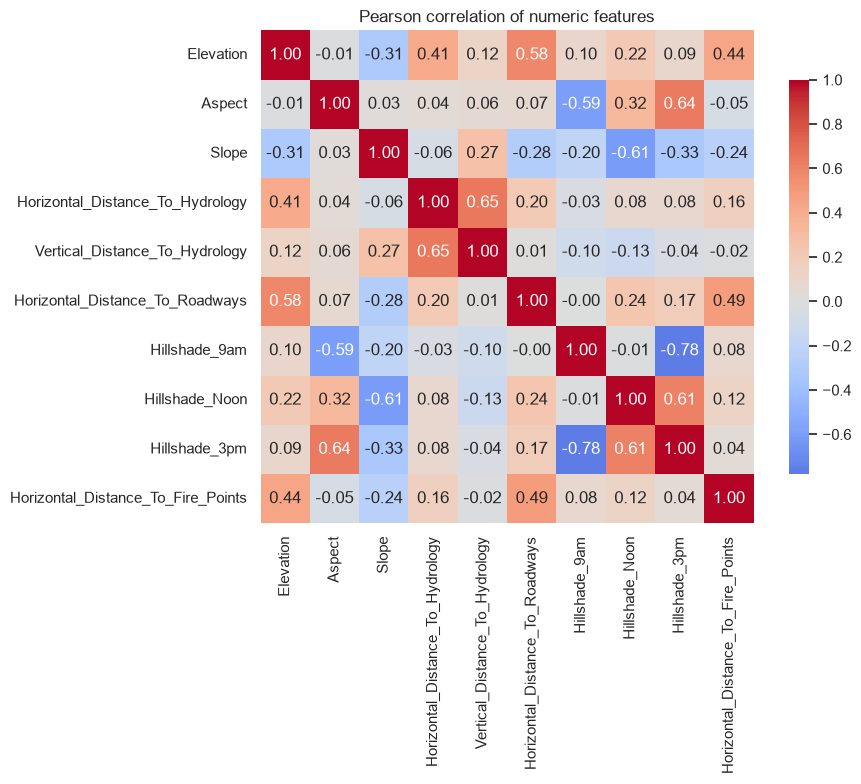

,level_0,level_1,corr
68,Hillshade_9am,Hillshade_3pm,-0.7800
34,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,0.6521
18,Aspect,Hillshade_3pm,0.6350
78,Hillshade_Noon,Hillshade_3pm,0.6145
27,Slope,Hillshade_Noon,-0.6126
16,Aspect,Hillshade_9am,-0.5940


In [10]:
corr = df[NUM].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Pearson correlation of numeric features"); plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("corr").reset_index().assign(abs_corr=lambda t: t["corr"].abs())
         .sort_values("abs_corr", ascending=False).head(6).drop(columns="abs_corr"))
pairs

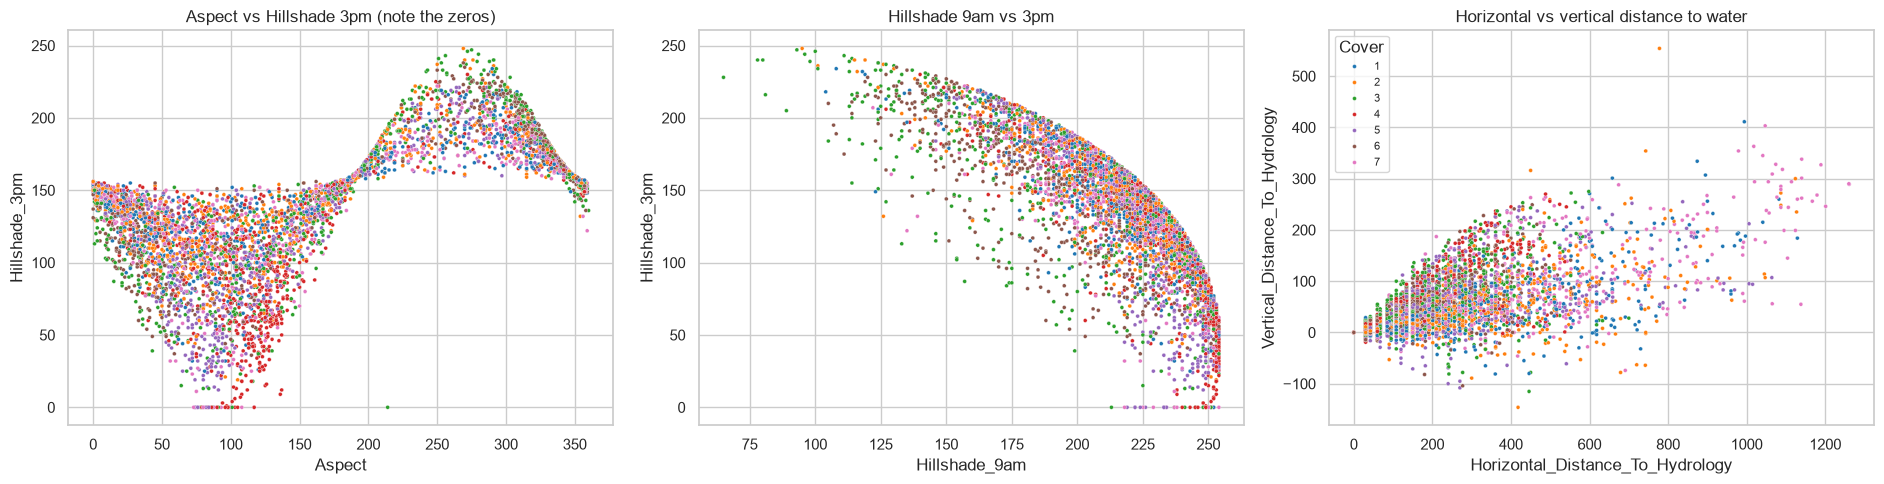

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sample = df.sample(5000, random_state=SEED)
sns.scatterplot(data=sample, x="Aspect", y="Hillshade_3pm", hue=TARGET, palette="tab10", s=8, ax=axes[0], legend=False)
axes[0].set_title("Aspect vs Hillshade 3pm (note the zeros)")
sns.scatterplot(data=sample, x="Hillshade_9am", y="Hillshade_3pm", hue=TARGET, palette="tab10", s=8, ax=axes[1], legend=False)
axes[1].set_title("Hillshade 9am vs 3pm")
sns.scatterplot(data=sample, x="Horizontal_Distance_To_Hydrology", y="Vertical_Distance_To_Hydrology",
                hue=TARGET, palette="tab10", s=8, ax=axes[2])
axes[2].set_title("Horizontal vs vertical distance to water"); axes[2].legend(title="Cover", fontsize=8)
plt.tight_layout(); plt.show()

**Correlation findings**

- The strongest pairs are physical: **Hillshade_9am vs Hillshade_3pm (−0.78)**, since a slope lit in the morning
  is shaded in the afternoon. Next come horizontal vs vertical distance to water (+0.65) and Aspect vs Hillshade_3pm (+0.64).
- No pair is close to ±1, so no feature duplicates another. All are kept.
- The scatter plots show hillshade forming curves determined by aspect and slope. That is why a missing hillshade
  value can be predicted from the other columns (section 8).
- Note: linear correlation with `Cover_Type` is close to 0 for *every* feature, even elevation (+0.02). The target
  codes 1–7 are labels, not quantities, so a linear correlation with them means nothing. The class-wise box plots
  and KDEs above are the right way to judge how useful a feature is.

### 5.4 Outliers and special values

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

special = pd.DataFrame({
    "IQR outliers": df[NUM].apply(iqr_outliers),
    "zeros": (df[NUM] == 0).sum(),
    "negatives": (df[NUM] < 0).sum(),
    "min": df[NUM].min(),
    "max": df[NUM].max(),
})
special["IQR outlier %"] = special["IQR outliers"] / len(df) * 100
special

,IQR outliers,zeros,negatives,min,max,IQR outlier %
Elevation,0,0,0,1863,3849,0.0000
Aspect,0,110,0,0,360,0.0000
Slope,57,5,0,0,52,0.3770
Horizontal_Distance_To_Hydrology,512,1590,0,0,1343,3.3862
Vertical_Distance_To_Hydrology,586,1890,1139,-146,554,3.8757
Horizontal_Distance_To_Roadways,830,3,0,0,6890,5.4894
Hillshade_9am,408,1,0,0,254,2.6984
Hillshade_Noon,393,0,0,99,254,2.5992
Hillshade_3pm,124,88,0,0,248,0.8201
Horizontal_Distance_To_Fire_Points,645,2,0,0,6993,4.2659


In [13]:
hs0 = df[df["Hillshade_3pm"] == 0]
print(f"Rows with Hillshade_3pm == 0: {len(hs0)}")
print("Cover types of those rows:", hs0[TARGET].value_counts().sort_index().to_dict())
print("Their Hillshade_9am range:", hs0["Hillshade_9am"].min(), "-", hs0["Hillshade_9am"].max(),
      "| Aspect range:", hs0["Aspect"].min(), "-", hs0["Aspect"].max())

Rows with Hillshade_3pm == 0: 88
Cover types of those rows: {1: 4, 3: 13, 4: 30, 5: 23, 7: 18}
Their Hillshade_9am range: 203 - 254 | Aspect range: 47 - 214


**Outliers and special values**

- The IQR rule flags up to 5.5% of rows in a column: most in roads (830), fire points (645) and the water distances.
  These are **real terrain**, not errors: long distances to a road or water source, and very shaded or very bright
  slopes. They are kept. Tree models split on thresholds, so extreme values do not distort them.
- `Horizontal_Distance_To_Hydrology == 0` for 1,590 rows: cells that touch water. These are valid.
- `Hillshade_3pm == 0` for **88 rows**. These are steep (median slope 38°), east- to south-east-facing slopes
  (aspect 47–214°) with bright mornings (Hillshade_9am 203–254). Rows with a similar aspect and slope also have very
  low 3pm values (median about 22, some as low as 1). So the zeros may be **real deep shade cut off at 0**, or a
  placeholder for "not recorded". The data cannot settle which.
  - We test both treatments: keep the zeros, or replace them with a value predicted from aspect, slope and the
    other hillshades (section 8). The comparison in section 10.1 decides which to use.

## 6. Wilderness areas

Wilderness columns set per row: {1: 15120}


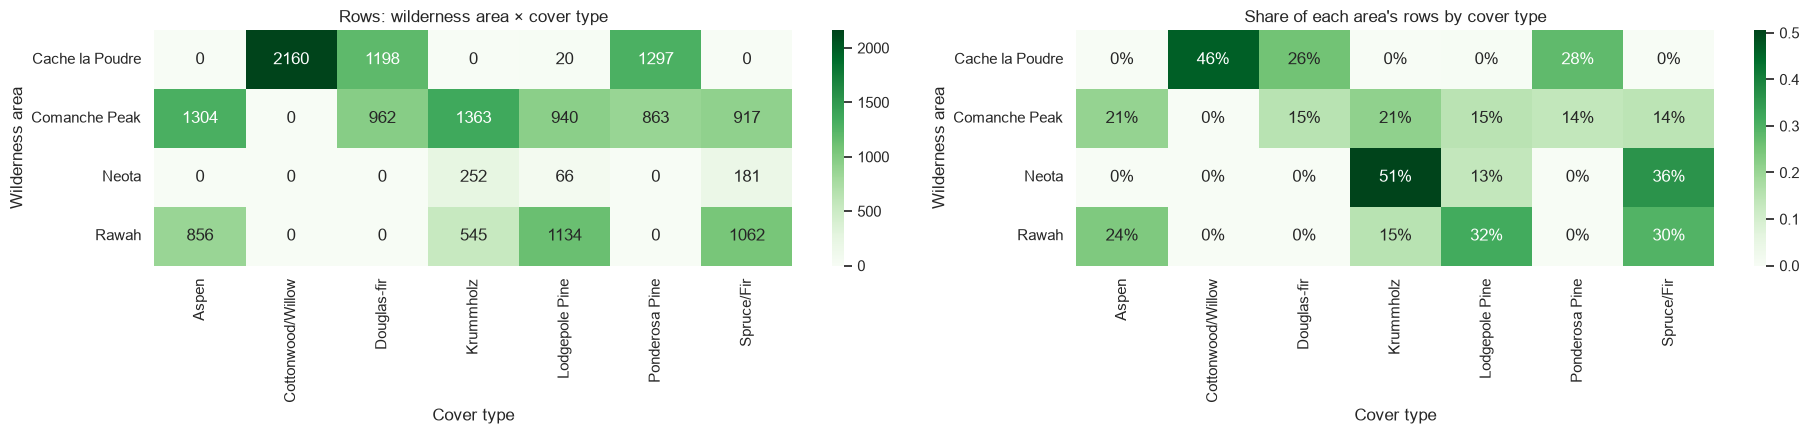

Cover type,Aspen,Cottonwood/Willow,Douglas-fir,Krummholz,Lodgepole Pine,Ponderosa Pine,Spruce/Fir,total
Wilderness area,,,,,,,,
Cache la Poudre,0,2160,1198,0,20,1297,0,4675
Comanche Peak,1304,0,962,1363,940,863,917,6349
Neota,0,0,0,252,66,0,181,499
Rawah,856,0,0,545,1134,0,1062,3597


In [14]:
print("Wilderness columns set per row:", df[WILD].sum(axis=1).value_counts().to_dict())
wild_id = df[WILD].to_numpy().argmax(axis=1) + 1
wild_ct = pd.crosstab(pd.Series(wild_id, name="Wilderness area").map(WILD_NAMES),
                      df[TARGET].map(COVER_NAMES).rename("Cover type"))
fig, axes = plt.subplots(1, 2, figsize=(19, 4.5))
sns.heatmap(wild_ct, annot=True, fmt="d", cmap="Greens", ax=axes[0]); axes[0].set_title("Rows: wilderness area × cover type")
sns.heatmap(wild_ct.div(wild_ct.sum(axis=1), axis=0), annot=True, fmt=".0%", cmap="Greens", ax=axes[1])
axes[1].set_title("Share of each area's rows by cover type")
plt.tight_layout(); plt.show()
wild_ct.assign(total=wild_ct.sum(axis=1))

**Wilderness-area findings**

- Every row has **exactly one** wilderness area set, so the four columns are a clean one-hot encoding of a single variable.
- The area alone narrows the choice a lot:
  - **Cottonwood/Willow (4) is found only in Cache la Poudre**, and Cache la Poudre has only types 2, 3, 4 and 6.
  - Types 3 and 6 never appear in Rawah or Neota.
  - Neota is small (499 rows) and holds only types 1, 2 and 7.
- Comanche Peak is the only area with all 7 types, so that is where the model must rely most on terrain and soil.

## 7. Soil types

Soil columns set per row: {1: 15120}


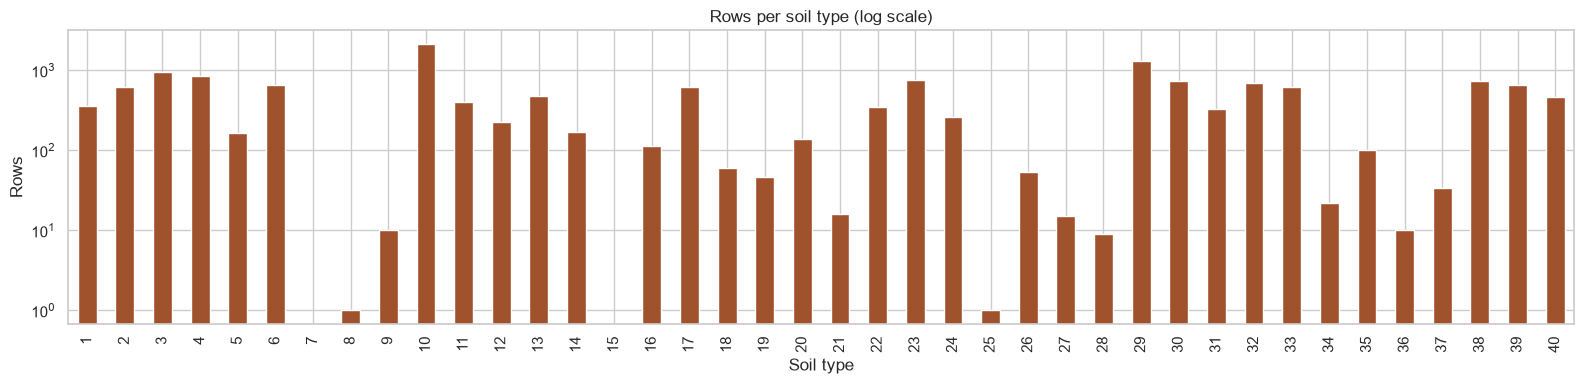

Soil types with no rows (constant columns): [7, 15]
Soil types with < 20 rows: {8: 1, 9: 10, 21: 16, 25: 1, 27: 15, 28: 9, 36: 10}


In [15]:
print("Soil columns set per row:", df[SOIL].sum(axis=1).value_counts().to_dict())
soil_counts = df[SOIL].sum().astype(int)
soil_counts.index = soil_counts.index.str.replace("Soil_Type", "").astype(int)
ax = soil_counts.plot.bar(figsize=(16, 4), color="sienna")
ax.set(title="Rows per soil type (log scale)", xlabel="Soil type", ylabel="Rows", yscale="log")
plt.tight_layout(); plt.show()

print("Soil types with no rows (constant columns):", soil_counts[soil_counts == 0].index.tolist())
print("Soil types with < 20 rows:", soil_counts[(soil_counts > 0) & (soil_counts < 20)].to_dict())

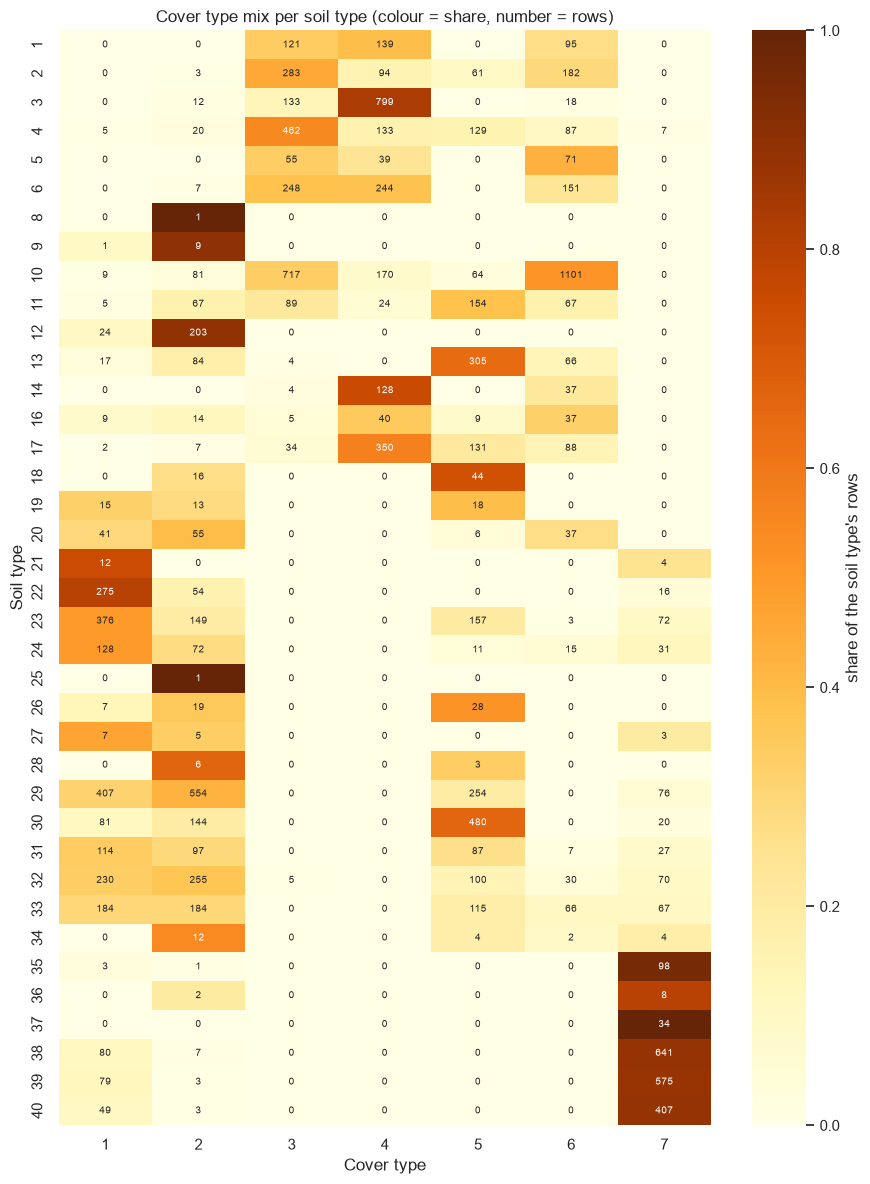

Soil types where one cover type makes up >= 90% of rows: 5 of 38
Rows on those soil types: 148


In [16]:
soil_id = pd.Series(df[SOIL].to_numpy().argmax(axis=1) + 1, name="Soil type")
soil_ct = pd.crosstab(soil_id, df[TARGET].rename("Cover type"))
plt.figure(figsize=(9, 12))
sns.heatmap(soil_ct.div(soil_ct.sum(axis=1), axis=0), cmap="YlOrBr", annot=soil_ct, fmt="d",
            cbar_kws={"label": "share of the soil type's rows"}, annot_kws={"size": 7})
plt.title("Cover type mix per soil type (colour = share, number = rows)"); plt.tight_layout(); plt.show()

purity = soil_ct.max(axis=1) / soil_ct.sum(axis=1)
print(f"Soil types where one cover type makes up >= 90% of rows: {(purity >= .9).sum()} of {len(purity)}")
print(f"Rows on those soil types: {soil_ct[purity >= .9].to_numpy().sum():,}")

**Soil-type findings**

- Every row has **exactly one** soil type, so it is a 40-level variable spread over 40 binary columns.
- **Soil types 7 and 15 never occur.** Those columns are always 0 and are dropped.
- Soil types 8 and 25 have one row each and 28 has nine, so they are very sparse.
- Usage is very uneven: soil 10 alone covers 2,142 rows, and the five largest soil types (10, 29, 3, 4, 23) cover 40% of the data.
- Many soil types are dominated by two or three cover types (the heatmap), so soil is an informative signal.
  But only 5 soil types (148 rows) belong to a single cover type ≥ 90% of the time, so soil alone does not decide the class.

### Task 1 summary — key takeaways from the data analysis

1. The data is **clean**: no missing values, no duplicates, consistent one-hot columns, a perfectly balanced target.
2. **Elevation is the dominant feature.** Wilderness area and soil type remove whole classes from consideration.
3. The likely hard cases are classes that overlap in elevation: **1 Spruce/Fir vs 2 Lodgepole Pine**, and
   **3 Ponderosa Pine vs 6 Douglas-fir**.
4. Problems to handle before modelling:
   - two constant soil columns;
   - 88 hillshade zeros that look like missing values;
   - aspect being an angle (359° sits next to 1°);
   - skewed distances on very different scales.
5. The relationships are non-linear and depend on combinations of features (for example, elevation *within* a wilderness area).
   That points to tree ensembles over linear models.

# Task 2 — Predictive Model

**Modelling approach.**
- Every preprocessing step is inside a scikit-learn `Pipeline`, so cross-validation never sees statistics
  computed from its own validation fold.
- Linear, distance and kernel models get standardised inputs. Tree models get the unscaled features (scaling changes nothing for them).
- All models get the same feature engineering, so they are compared on equal terms.

## 8. Preprocessing and feature engineering

In [17]:
class ForestFeatures(BaseEstimator, TransformerMixin):
    """Cleans and enriches the raw columns. Anything learned (the Hillshade_3pm imputer and the
    list of constant columns) is learned in fit() on training data only, so it is safe inside CV."""

    HS_INPUTS = ["Aspect", "Slope", "Hillshade_9am", "Hillshade_Noon"]

    def __init__(self, impute_hillshade=True, add_features=True):
        self.impute_hillshade = impute_hillshade
        self.add_features = add_features

    def fit(self, X, y=None):
        X = X.drop(columns=["Id", TARGET], errors="ignore")
        if self.impute_hillshade:
            known = X["Hillshade_3pm"] > 0
            self.hs_model_ = HistGradientBoostingRegressor(random_state=SEED).fit(
                X.loc[known, self.HS_INPUTS], X.loc[known, "Hillshade_3pm"])
        self.constant_cols_ = [c for c in X.columns if X[c].nunique() <= 1]
        self.feature_names_out_ = self._transform(X).columns.to_numpy()
        return self

    def _transform(self, X):
        X = X.drop(columns=["Id", TARGET], errors="ignore").copy()
        if self.impute_hillshade:
            missing = X["Hillshade_3pm"] == 0
            if missing.any():
                X.loc[missing, "Hillshade_3pm"] = np.clip(
                    self.hs_model_.predict(X.loc[missing, self.HS_INPUTS]), 0, 255).round().astype(X["Hillshade_3pm"].dtype)
        if self.add_features:
            hd, vd = X["Horizontal_Distance_To_Hydrology"], X["Vertical_Distance_To_Hydrology"]
            road, fire = X["Horizontal_Distance_To_Roadways"], X["Horizontal_Distance_To_Fire_Points"]
            elev = X["Elevation"]
            rad = np.deg2rad(X["Aspect"])
            new = {
                "Hydro_Euclid": np.hypot(hd, vd),
                "Elev_minus_VDH": elev - vd,            # elevation of the nearest water
                "Elev_minus_HDH": elev - 0.2 * hd,
                "Hydro_Fire_sum": hd + fire, "Hydro_Fire_diff": (hd - fire).abs(),
                "Hydro_Road_sum": hd + road, "Hydro_Road_diff": (hd - road).abs(),
                "Fire_Road_sum": fire + road, "Fire_Road_diff": (fire - road).abs(),
                "Aspect_sin": np.sin(rad), "Aspect_cos": np.cos(rad),
                "Hillshade_mean": X[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]].mean(axis=1),
                "Wilderness_id": X[WILD].to_numpy().argmax(axis=1) + 1,
                "Soil_id": X[SOIL].to_numpy().argmax(axis=1) + 1,
            }
            X = pd.concat([X, pd.DataFrame(new, index=X.index)], axis=1)
        return X.drop(columns=getattr(self, "constant_cols_", []))

    def transform(self, X):
        return self._transform(X)

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_

In [18]:
# How well can Hillshade_3pm be recovered from the other columns? (checked on rows where it is known)
known = df[df["Hillshade_3pm"] > 0]
hs_r2 = cross_val_score(HistGradientBoostingRegressor(random_state=SEED), known[ForestFeatures.HS_INPUTS],
                        known["Hillshade_3pm"], cv=5, scoring="r2")
print(f"Hillshade_3pm imputer, 5-fold R² on known rows: {hs_r2.mean():.4f} ± {hs_r2.std():.4f}")

demo = ForestFeatures().fit(df.drop(columns=TARGET))
print(f"Columns after feature engineering: {len(demo.get_feature_names_out())}")
print("Dropped as constant:", demo.constant_cols_)

Hillshade_3pm imputer, 5-fold R² on known rows: 0.9994 ± 0.0001


Columns after feature engineering: 66
Dropped as constant: ['Soil_Type7', 'Soil_Type15']


## 9. Train / test split and validation scheme

In [19]:
X = df.drop(columns=["Id", TARGET])
y = df[TARGET] - 1            # classes 0..6 for the models (XGBoost requires 0-based labels); +1 when reporting
LABELS = [f"{k} {v}" for k, v in COVER_NAMES.items()]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Test rows per class:", y_test.value_counts().sort_index().to_dict())

Train: (12096, 54)  Test: (3024, 54)
Test rows per class: {0: 432, 1: 432, 2: 432, 3: 432, 4: 432, 5: 432, 6: 432}


**Validation scheme.**
- 20% of the rows (3,024, i.e. 432 per class) are held out as a **test set**. It is used once, at the end.
- All model selection and tuning use **5-fold stratified cross-validation** on the remaining 12,096 rows.
- Both splits keep the 1/7 class balance.

## 10. Baseline comparison of models (5-fold CV on the training set)

In [20]:
def make_pipe(model, scale=False, features=True, impute=True):
    steps = [("features", ForestFeatures(impute_hillshade=impute, add_features=features))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

candidates = {
    "Dummy (most frequent)": make_pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression":   make_pipe(LogisticRegression(max_iter=3000, C=1.0), scale=True),
    "KNN (k=5)":             make_pipe(KNeighborsClassifier(n_neighbors=5, weights="distance"), scale=True),
    "SVM (RBF)":             make_pipe(SVC(C=10, gamma="scale", random_state=SEED), scale=True),
    "Decision Tree":         make_pipe(DecisionTreeClassifier(random_state=SEED)),
    "Random Forest":         make_pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
    "Extra Trees":           make_pipe(ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
    "XGBoost":               make_pipe(XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=8,
                                                     tree_method="hist", n_jobs=-1, random_state=SEED)),
    "LightGBM":              make_pipe(LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63,
                                                      n_jobs=-1, random_state=SEED, verbose=-1)),
}

def cv_summary(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=1)
    return {"cv_accuracy": r["test_accuracy"].mean(), "cv_accuracy_std": r["test_accuracy"].std(),
            "cv_f1_macro": r["test_f1_macro"].mean(), "fit_time_s": r["fit_time"].mean(),
            "predict_time_s": r["score_time"].mean()}

rows = {}
for name, pipe in candidates.items():
    t0 = time.perf_counter()
    rows[name] = cv_summary(pipe)
    print(f"{name:<24} acc={rows[name]['cv_accuracy']:.4f}  ({time.perf_counter() - t0:.1f}s)")

baseline = pd.DataFrame(rows).T.sort_values("cv_accuracy", ascending=False)
baseline

Dummy (most frequent)    acc=0.1426  (1.6s)


Logistic Regression      acc=0.7167  (3.9s)


KNN (k=5)                acc=0.8051  (1.7s)


SVM (RBF)                acc=0.8132  (10.8s)


Decision Tree            acc=0.7889  (2.6s)


Random Forest            acc=0.8800  (6.3s)


Extra Trees              acc=0.8914  (5.1s)


XGBoost                  acc=0.8786  (25.8s)


LightGBM                 acc=0.8849  (28.3s)


,cv_accuracy,cv_accuracy_std,cv_f1_macro,fit_time_s,predict_time_s
Extra Trees,0.8914,0.0029,0.8901,0.8445,0.1344
LightGBM,0.8849,0.0047,0.8835,5.5583,0.0930
Random Forest,0.8800,0.0040,0.8782,1.1077,0.1349
XGBoost,0.8786,0.0040,0.8770,5.1048,0.0475
SVM (RBF),0.8132,0.0078,0.8105,1.3129,0.8494
KNN (k=5),0.8051,0.0036,0.8006,0.2802,0.0615
Decision Tree,0.7889,0.0068,0.7883,0.4957,0.0140
Logistic Regression,0.7167,0.0087,0.7138,0.7560,0.0173
Dummy (most frequent),0.1426,0.0000,0.0357,0.2913,0.0157


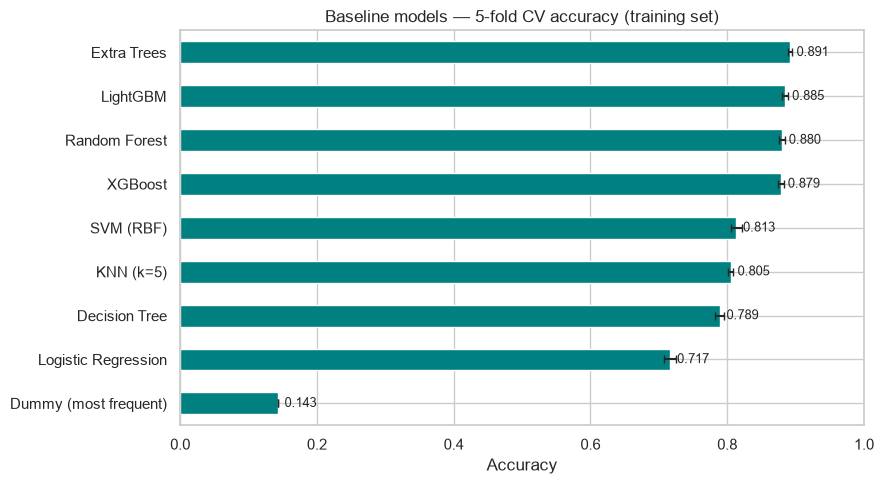

In [21]:
ax = baseline["cv_accuracy"].iloc[::-1].plot.barh(xerr=baseline["cv_accuracy_std"].iloc[::-1],
                                                  figsize=(9, 5), color="teal", capsize=3)
ax.set(title="Baseline models — 5-fold CV accuracy (training set)", xlabel="Accuracy", xlim=(0, 1))
for i, v in enumerate(baseline["cv_accuracy"].iloc[::-1]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Baseline findings** (accuracy figures are from the cross-validation run):

- **Tree ensembles lead clearly:** Extra Trees 89.1%, LightGBM 88.5%, Random Forest 88.0%, XGBoost 87.9%.
- Next come the distance and kernel models: SVM 81.3%, KNN 80.5%. Then a single decision tree (78.9%) and
  logistic regression (71.7%).
- Every model is far above the 14.3% chance level.
- Logistic regression trails because the class boundaries are not linear. For example, "Aspen" means a *middle*
  elevation band, which a single linear weight on elevation cannot express.
- Fold-to-fold spread is small (0.3–0.9 points), so a gap of more than about 1 point between models is real.

### 10.1 Does the feature engineering help?

In [22]:
ablation = {}
for name in ["Random Forest", "Extra Trees", "LightGBM"]:
    model = candidates[name].named_steps["model"]
    variants = {"raw features": dict(features=False, impute=False),
                "raw + hillshade imputation": dict(features=False, impute=True),
                "engineered, no imputation": dict(features=True, impute=False),
                "engineered + imputation": dict(features=True, impute=True)}
    ablation[name] = {v: cv_summary(make_pipe(clone(model), **kw))["cv_accuracy"] for v, kw in variants.items()}
ablation = pd.DataFrame(ablation).T
ablation["feature gain (pts)"] = (ablation["engineered, no imputation"] - ablation["raw features"]) * 100
ablation["imputation gain (pts)"] = (ablation["engineered + imputation"] - ablation["engineered, no imputation"]) * 100
ablation

,raw features,raw + hillshade imputation,"engineered, no imputation",engineered + imputation,feature gain (pts),imputation gain (pts)
Random Forest,0.8581,0.8587,0.8791,0.8800,2.0916,0.0992
Extra Trees,0.8590,0.8564,0.8901,0.8914,3.1167,0.1240
LightGBM,0.8669,0.8652,0.8846,0.8849,1.7692,0.0331


**Feature-engineering findings**

- The engineered features add **+1.8 to +3.1 accuracy points** to every tree ensemble (Extra Trees: 85.9% → 89.0%).
  That is the largest single improvement in the project, bigger than any tuning gain below.
- The Hillshade_3pm fill-in changes accuracy by only **+0.03 to +0.12 points** once the engineered features are
  present. That is smaller than the fold-to-fold spread, so it is **effectively neutral**: the 88 affected rows are
  too few to matter. We keep it because it never hurt and gives physically plausible values, but we don't claim it helps.

## 11. Hyper-parameter tuning of the tree ensembles

In [23]:
# Search uses 3-fold CV and 10 random draws per model to keep run time reasonable; the winning
# setting is then re-scored with the same 5-fold CV as the baselines so the numbers are comparable.
search_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search_spaces = {
    "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=SEED), {
        "model__n_estimators": [200, 400],
        "model__max_features": ["sqrt", 0.3, 0.5],
        "model__min_samples_leaf": [1, 2],
        "model__max_depth": [None, 30],
        "model__bootstrap": [True, False]}),
    "Extra Trees": (ExtraTreesClassifier(n_jobs=-1, random_state=SEED), {
        "model__n_estimators": [300, 500],
        "model__max_features": ["sqrt", 0.3, 0.5, 0.7],
        "model__min_samples_leaf": [1, 2],
        "model__max_depth": [None, 40],
        "model__bootstrap": [False, True]}),
    "XGBoost": (XGBClassifier(tree_method="hist", n_jobs=-1, random_state=SEED), {
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [6, 8, 10],
        "model__learning_rate": [0.05, 0.1, 0.2],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__min_child_weight": [1, 3]}),
    "LightGBM": (LGBMClassifier(n_jobs=-1, random_state=SEED, verbose=-1, subsample_freq=1), {
        "model__n_estimators": [300, 600, 900],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__num_leaves": [31, 63, 127],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__min_child_samples": [5, 10, 20],
        "model__reg_lambda": [0, 1, 5]}),
}

tuned, tuning_rows = {}, {}
for name, (model, grid) in search_spaces.items():
    t0 = time.perf_counter()
    search = RandomizedSearchCV(make_pipe(model), grid, n_iter=10, cv=search_cv, scoring="accuracy",
                                random_state=SEED, n_jobs=1, refit=False)
    search.fit(X_train, y_train)
    tuned[name] = make_pipe(clone(model)).set_params(**search.best_params_)
    rescored = cv_summary(tuned[name])
    tuning_rows[name] = {"baseline_cv_accuracy": baseline.loc[name, "cv_accuracy"],
                         "tuned_cv_accuracy": rescored["cv_accuracy"],
                         "tuned_cv_std": rescored["cv_accuracy_std"],
                         "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()}}
    print(f"{name:<14} 3-fold search best={search.best_score_:.4f} | 5-fold re-score={rescored['cv_accuracy']:.4f}"
          f"  ({time.perf_counter() - t0:.0f}s)")

tuning = pd.DataFrame(tuning_rows).T
with pd.option_context("display.max_colwidth", None):
    display(tuning)

Random Forest  3-fold search best=0.8808 | 5-fold re-score=0.8914  (170s)


Extra Trees    3-fold search best=0.8834 | 5-fold re-score=0.8935  (52s)


XGBoost        3-fold search best=0.8714 | 5-fold re-score=0.8794  (202s)


LightGBM       3-fold search best=0.8738 | 5-fold re-score=0.8807  (351s)


,baseline_cv_accuracy,tuned_cv_accuracy,tuned_cv_std,best_params
Random Forest,0.8800,0.8914,0.0037,"{'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30, 'bootstrap': False}"
Extra Trees,0.8914,0.8935,0.0045,"{'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None, 'bootstrap': False}"
XGBoost,0.8786,0.8794,0.0036,"{'subsample': 0.85, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.9}"
LightGBM,0.8849,0.8807,0.0016,"{'subsample': 1.0, 'reg_lambda': 1, 'num_leaves': 127, 'n_estimators': 600, 'min_child_samples': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.7}"


### 11.1 Soft-voting ensemble of the best three tuned models

In [24]:
top3 = tuning["tuned_cv_accuracy"].astype(float).nlargest(3).index.tolist()
print("Ensemble members:", top3)
ensemble = VotingClassifier([(n.replace(" ", "_"), clone(tuned[n])) for n in top3], voting="soft", n_jobs=1)
ens_cv = cv_summary(ensemble)
print(f"Soft-voting ensemble CV accuracy: {ens_cv['cv_accuracy']:.4f} ± {ens_cv['cv_accuracy_std']:.4f}")

Ensemble members: ['Extra Trees', 'Random Forest', 'LightGBM']


Soft-voting ensemble CV accuracy: 0.8889 ± 0.0023


## 12. Final evaluation on the held-out test set

In [25]:
final_models = {**{f"{n} (tuned)": tuned[n] for n in tuned},
                "Soft-voting ensemble": ensemble,
                "Logistic Regression": candidates["Logistic Regression"],
                "KNN (k=5)": candidates["KNN (k=5)"],
                "SVM (RBF)": candidates["SVM (RBF)"],
                "Decision Tree": candidates["Decision Tree"]}

cv_lookup = {**{f"{n} (tuned)": tuning.loc[n, "tuned_cv_accuracy"] for n in tuned},
             "Soft-voting ensemble": ens_cv["cv_accuracy"],
             **{n: baseline.loc[n, "cv_accuracy"] for n in ["Logistic Regression", "KNN (k=5)", "SVM (RBF)", "Decision Tree"]}}

tmp_path = MODEL_DIR / "_size_check.joblib"
fitted, report_rows = {}, {}
for name, pipe in final_models.items():
    pipe = clone(pipe)
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = pipe.predict(X_test); pred_s = time.perf_counter() - t0
    joblib.dump(pipe, tmp_path)
    fitted[name] = pipe
    report_rows[name] = {"cv_accuracy": float(cv_lookup[name]),
                         "test_accuracy": accuracy_score(y_test, pred),
                         "test_f1_macro": f1_score(y_test, pred, average="macro"),
                         "train_time_s": fit_s,
                         "predict_ms_per_1k_rows": pred_s / len(X_test) * 1e6,
                         "model_size_mb": tmp_path.stat().st_size / 1e6}
tmp_path.unlink(missing_ok=True)

comparison = pd.DataFrame(report_rows).T.sort_values("test_accuracy", ascending=False)
comparison

,cv_accuracy,test_accuracy,test_f1_macro,train_time_s,predict_ms_per_1k_rows,model_size_mb
Extra Trees (tuned),0.8935,0.8968,0.8952,1.8984,74.7809,348.5462
Random Forest (tuned),0.8914,0.8925,0.8909,1.8945,58.1078,206.0020
Soft-voting ensemble,0.8889,0.8925,0.8907,17.7953,202.6739,608.8924
LightGBM (tuned),0.8807,0.8853,0.8832,13.7793,64.0617,54.3720
XGBoost (tuned),0.8794,0.8816,0.8796,7.9968,16.8184,14.8453
KNN (k=5),0.8051,0.8237,0.8193,0.3143,24.3174,6.8585
SVM (RBF),0.8132,0.8201,0.8169,1.9416,462.1100,4.3083
Decision Tree,0.7889,0.7966,0.7956,0.5437,3.0407,0.7271
Logistic Regression,0.7167,0.7001,0.6978,0.9702,4.9574,0.3788


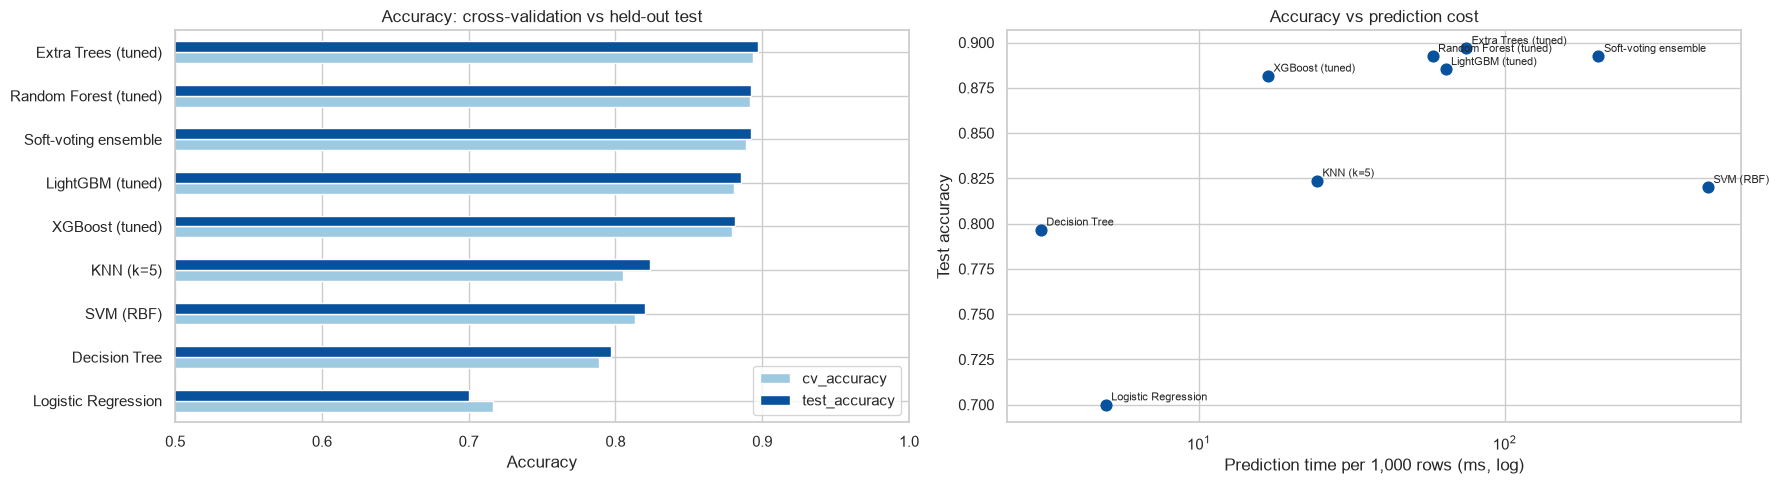

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
c = comparison.iloc[::-1]
c[["cv_accuracy", "test_accuracy"]].plot.barh(ax=axes[0], color=["#9ecae1", "#08519c"])
axes[0].set(title="Accuracy: cross-validation vs held-out test", xlabel="Accuracy", xlim=(0.5, 1))
axes[0].legend(loc="lower right")
axes[1].scatter(comparison["predict_ms_per_1k_rows"], comparison["test_accuracy"], s=60, color="#08519c")
for n, r in comparison.iterrows():
    axes[1].annotate(n, (r["predict_ms_per_1k_rows"], r["test_accuracy"]), fontsize=8,
                     xytext=(4, 3), textcoords="offset points")
axes[1].set(xscale="log", title="Accuracy vs prediction cost", xlabel="Prediction time per 1,000 rows (ms, log)",
            ylabel="Test accuracy")
plt.tight_layout(); plt.show()

### 12.1 Detailed results for the recommended model

In [27]:
BEST_NAME = "Extra Trees (tuned)"   # chosen in the Model Comparison Report (section 14)
best = fitted[BEST_NAME]
pred = best.predict(X_test)
print(f"{BEST_NAME} — test accuracy {accuracy_score(y_test, pred):.4f}, macro F1 {f1_score(y_test, pred, average='macro'):.4f}\n")
print(classification_report(y_test, pred, target_names=LABELS, digits=4))

Extra Trees (tuned) — test accuracy 0.8968, macro F1 0.8952

                     precision    recall  f1-score   support

       1 Spruce/Fir     0.8290    0.8194    0.8242       432
   2 Lodgepole Pine     0.8153    0.7153    0.7620       432
   3 Ponderosa Pine     0.8793    0.8935    0.8863       432
4 Cottonwood/Willow     0.9571    0.9815    0.9691       432
            5 Aspen     0.9211    0.9722    0.9459       432
      6 Douglas-fir     0.9023    0.9190    0.9106       432
        7 Krummholz     0.9591    0.9769    0.9679       432

           accuracy                         0.8968      3024
          macro avg     0.8947    0.8968    0.8952      3024
       weighted avg     0.8947    0.8968    0.8952      3024



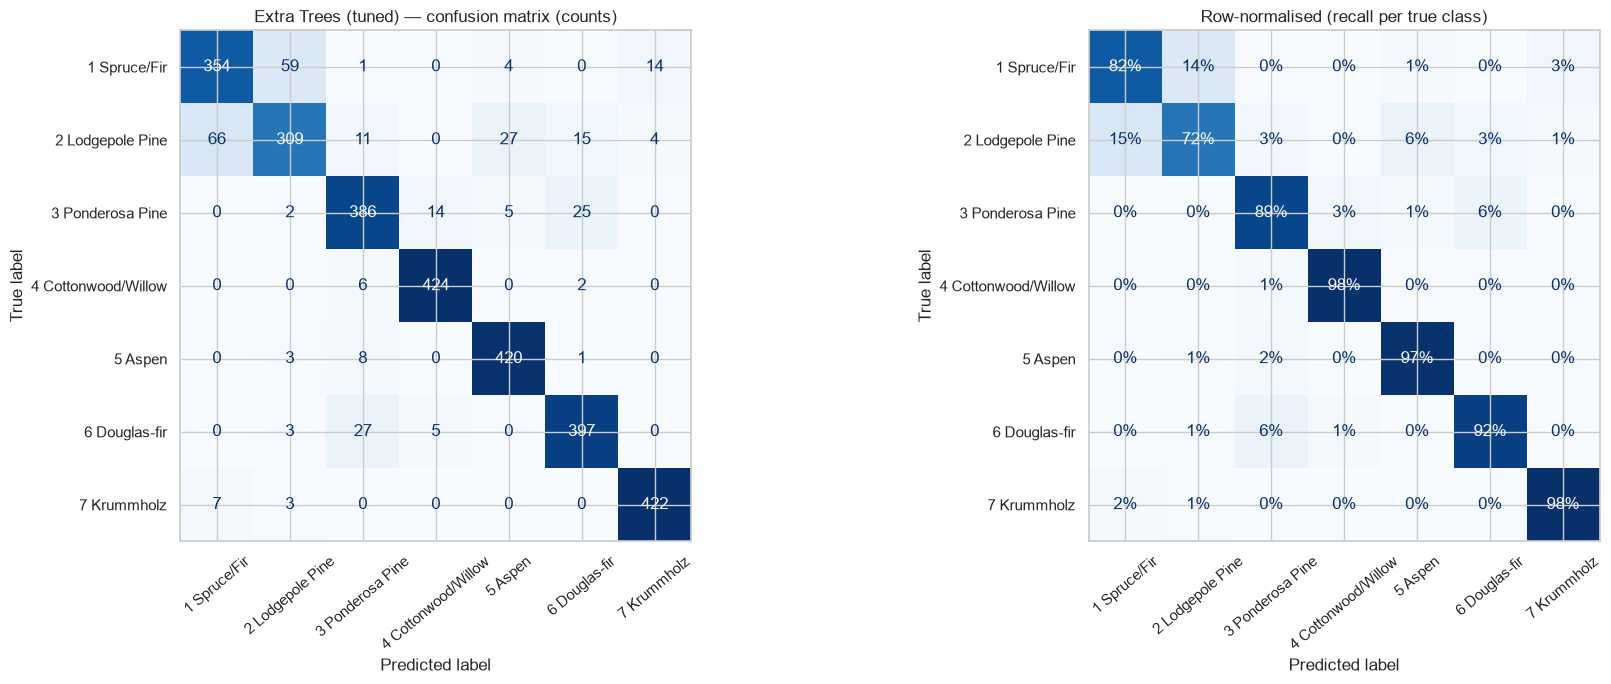

Most frequent mistakes (true → predicted):
2 Lodgepole Pine  1 Spruce/Fir        66
1 Spruce/Fir      2 Lodgepole Pine    59
2 Lodgepole Pine  5 Aspen             27
6 Douglas-fir     3 Ponderosa Pine    27
3 Ponderosa Pine  6 Douglas-fir       25


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(19, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=LABELS).plot(
    ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=40)
axes[0].set_title(f"{BEST_NAME} — confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, normalize="true"), display_labels=LABELS).plot(
    ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=40, values_format=".0%")
axes[1].set_title("Row-normalised (recall per true class)")
plt.tight_layout(); plt.show()

cm = pd.DataFrame(confusion_matrix(y_test, pred), index=LABELS, columns=LABELS)
off = cm.where(~np.eye(7, dtype=bool)).stack().sort_values(ascending=False).head(5)
print("Most frequent mistakes (true → predicted):"); print(off.astype(int).to_string())

### 12.2 Which features drive the predictions?

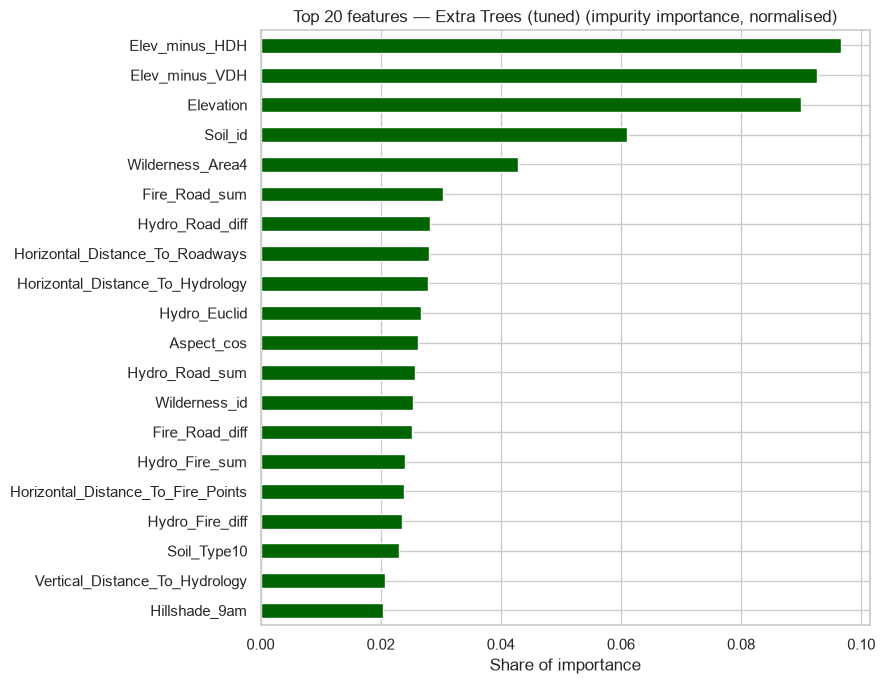

Engineered features in the top 10: ['Elev_minus_HDH', 'Elev_minus_VDH', 'Soil_id', 'Fire_Road_sum', 'Hydro_Road_diff', 'Hydro_Euclid']


In [29]:
def tree_importances(pipe):
    names = pipe.named_steps["features"].get_feature_names_out()
    imp = pipe.named_steps["model"].feature_importances_
    return pd.Series(imp / imp.sum(), index=names)

imp_model = BEST_NAME if isinstance(fitted[BEST_NAME], Pipeline) else "Extra Trees (tuned)"
imp = tree_importances(fitted[imp_model]).sort_values(ascending=False)
ax = imp.head(20).iloc[::-1].plot.barh(figsize=(9, 7), color="darkgreen")
ax.set(title=f"Top 20 features — {imp_model} (impurity importance, normalised)", xlabel="Share of importance")
plt.tight_layout(); plt.show()
engineered = [c for c in imp.index if c not in X.columns]
print(f"Engineered features in the top 10: {[c for c in imp.head(10).index if c in engineered]}")

### 12.3 How many trees does production need?

In [30]:
# The tuned Extra Trees model uses 500 trees and is ~350 MB in memory. Check whether fewer trees lose accuracy.
tree_rows = {}
for n in [100, 200, 300, 500]:
    p = clone(tuned["Extra Trees"]).set_params(model__n_estimators=n)
    s = cv_summary(p)
    p.fit(X_train, y_train)
    t0 = time.perf_counter(); acc = accuracy_score(y_test, p.predict(X_test)); pt = time.perf_counter() - t0
    joblib.dump(p, tmp_path, compress=3)
    tree_rows[n] = {"cv_accuracy": s["cv_accuracy"], "cv_std": s["cv_accuracy_std"], "test_accuracy": acc,
                    "saved_size_mb_compressed": tmp_path.stat().st_size / 1e6,
                    "predict_ms_per_1k_rows": pt / len(X_test) * 1e6}
tmp_path.unlink(missing_ok=True)
trees = pd.DataFrame(tree_rows).T.rename_axis("n_estimators")
trees

,cv_accuracy,cv_std,test_accuracy,saved_size_mb_compressed,predict_ms_per_1k_rows
n_estimators,,,,,
100,0.8930,0.0037,0.8978,10.7850,29.8705
200,0.8938,0.0047,0.8981,21.4345,43.6756
300,0.8934,0.0041,0.8975,32.0731,58.8586
500,0.8935,0.0045,0.8968,53.3474,83.4862


**Accuracy stops improving after about 100 trees.** From 100 to 500 trees, cross-validated accuracy stays within
±0.1 point, well inside the fold-to-fold spread. Size and prediction time, meanwhile, grow in step with the
number of trees.
- The production model uses **200 trees**: the same accuracy as 500, at about 40% of the size and prediction time.
- We chose 200 rather than 100 for a little extra stability, since more trees means predictions vary less between training runs.

## 13. Save the production model

In [31]:
PROD_TREES = 200   # see 12.3: same accuracy as 500 trees at ~40% of the size
# Refit the chosen pipeline on all 15,120 labelled rows before saving — the test set has done its job.
production = clone(final_models[BEST_NAME]).set_params(model__n_estimators=PROD_TREES).fit(X, y)
MODEL_PATH = MODEL_DIR / "forest_cover_model.joblib"
joblib.dump({"pipeline": production, "label_offset": 1, "cover_names": COVER_NAMES,
             "features": X.columns.tolist()}, MODEL_PATH, compress=3)
print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

# Usage: load and predict on raw rows with the same columns as train.csv (Id and Cover_Type optional).
# Note: the ForestFeatures class must be defined (or importable) wherever the model is loaded.
bundle = joblib.load(MODEL_PATH)
new_rows = df.drop(columns=[TARGET]).sample(5, random_state=1)
preds = bundle["pipeline"].predict(new_rows[bundle["features"]]) + bundle["label_offset"]
pd.DataFrame({"Id": new_rows["Id"].values, "predicted": preds,
              "predicted_name": [COVER_NAMES[p] for p in preds],
              "actual": df.loc[new_rows.index, TARGET].values})

Saved models\forest_cover_model.joblib (25.5 MB)


,Id,predicted,predicted_name,actual
0,5766,6,Douglas-fir,6
1,11341,1,Spruce/Fir,1
2,9271,7,Krummholz,7
3,5711,5,Aspen,5
4,1071,1,Spruce/Fir,1


# 14. Model Comparison Report

Nine models were trained on the same pipeline (same features, same 80/20 split, same 5-fold CV).
The four tree ensembles were then tuned, and a soft-voting ensemble of the best three was added.
Test-set figures come from the 3,024 held-out rows, used once.

| Model | CV accuracy | Test accuracy | Test macro F1 | Train time | Predict (ms / 1k rows) | Size (uncompressed) |
|---|---|---|---|---|---|---|
| **Extra Trees (tuned)** | **0.8935** | **0.8968** | **0.8952** | 2.0 s | 78 | 349 MB |
| Random Forest (tuned) | 0.8914 | 0.8925 | 0.8909 | 2.1 s | 57 | 206 MB |
| Soft-voting ensemble (ET + RF + LGBM) | 0.8889 | 0.8925 | 0.8907 | 17.3 s | 213 | 609 MB |
| LightGBM (tuned) | 0.8807 | 0.8853 | 0.8832 | 13.3 s | 66 | 54 MB |
| XGBoost (tuned) | 0.8794 | 0.8816 | 0.8796 | 7.6 s | 16 | 15 MB |
| KNN (k = 5) | 0.8051 | 0.8237 | 0.8193 | 0.3 s | 23 | 7 MB |
| SVM (RBF) | 0.8132 | 0.8201 | 0.8169 | 2.1 s | 439 | 4 MB |
| Decision Tree | 0.7889 | 0.7966 | 0.7956 | 0.6 s | 5 | 0.7 MB |
| Logistic Regression | 0.7167 | 0.7001 | 0.6978 | 0.9 s | 4 | 0.4 MB |

*(Times were measured on a 24-core machine during this run, so treat them as relative, not absolute.
The exact values are in the table in section 12.)*

**What the comparison shows**

1. **Extra Trees is the most accurate model** in cross-validation and on the test set. Random Forest is
   about 0.4 points behind. The boosting models are 1.2–1.5 points behind.
2. **Tuning helped Random Forest most** (+1.1 points), Extra Trees a little (+0.2), and XGBoost hardly at all (+0.1).
   For LightGBM, the 10-draw random search did *not* beat the hand-picked baseline setting (88.1% vs 88.5%).
   A longer search might close that gap, but would not change the ranking at the top.
3. **The ensemble did not pay off.** Its accuracy is slightly *below* Extra Trees alone, while it costs about 3× the
   prediction time and memory. Its members make similar mistakes, so averaging them adds little.
4. **CV and test accuracy agree closely.** Test accuracy is slightly *higher* for every top model, so tuning did not
   overfit the validation folds. The 89–90% figure is a fair estimate on data drawn like this sample.
5. **Where the best model still fails:**
   - The best model makes 312 test errors. **40% of them (125) are Spruce/Fir and Lodgepole Pine confused
     with each other.** The next most common mix-ups are Ponderosa Pine with Douglas-fir (52) and Lodgepole Pine
     predicted as Aspen (27).
   - Lodgepole Pine has the lowest recall (71.5%). Cottonwood/Willow, Krummholz and Aspen are each above 97%.

### Recommended model for production: **Extra Trees** (tuned settings, 200 trees)

Settings: `max_features=0.3`, `bootstrap=False`, no depth limit, `min_samples_leaf=1`, with the `ForestFeatures`
preprocessing step. Retrained on all 15,120 rows and saved as `models/forest_cover_model.joblib`.

Why this model:
- **Best accuracy:** about 89.7% test accuracy and 0.895 macro F1, the highest of all models. It is also among the
  most stable across folds (±0.4–0.5 points).
- **Cheap to run:** with 200 trees it is as accurate as with 500 (section 12.3), takes about 2 s to train, predicts
  thousands of rows per second, and is about 25 MB on disk once compressed.
- **Simple:** one model, no scaling step, no boosting rounds or learning rate to manage, and few settings that
  are sensitive.
- **Robust:** decisions are threshold-based, so outliers, skewed distances and unscaled features need no special handling.

**Alternative when memory is tight:** XGBoost (tuned) is about 15 MB in memory and the fastest to predict, at a cost
of about 1.5 accuracy points.

**Before going live:**
- **Class mix:** the training sample has equal counts of every cover type. The real forest does not: Spruce/Fir and
  Lodgepole Pine dominate. Accuracy on real-world cells will differ from 89.7%. Validate on a sample with the real
  class mix, and adjust the class priors if needed.
- **Packaging:** move the `ForestFeatures` class into a Python module, so the saved model can be loaded outside this notebook.

# 15. Report on Challenges Faced

| # | Challenge in the data / project | Technique used | Why this technique |
|---|---|---|---|
| 1 | **Soil type spread over 40 sparse binary columns.** Two (types 7 and 15) are always 0; three have 1–9 rows. | Constant columns are dropped (detected in `fit`, on training data only). A single integer `Soil_id` is added next to the binary columns, plus `Wilderness_id`. | Constant columns carry no information. A single code lets a tree group related soil types in one split instead of 40 separate ones. `Soil_id` ranks among the top-10 features. |
| 2 | **Very different scales and skewed distances** (slope 0–52 vs distances up to 7,000; skew up to 1.6). | `StandardScaler` inside the pipeline, **only** for logistic regression, KNN and SVM. Tree models use the raw values. No log transform. | Distance and gradient methods are distorted by scale. Trees split on thresholds and are unaffected by scaling or by monotone transforms such as log, and trees are the best models here, so extra transforms would add complexity for no gain. |
| 3 | **Aspect is an angle** (0° and 360° both mean north). | Added `Aspect_sin` and `Aspect_cos`. | As a plain number, 359° looks far from 1°. Sine and cosine put neighbouring directions next to each other. |
| 4 | **88 rows with Hillshade_3pm = 0** on steep east-facing slopes. These could be real deep shade or missing values, and the data cannot tell which. | A gradient-boosting regressor predicts the value from aspect, slope and the 9am/noon hillshade (R² = 0.999 on known rows). It is trained inside the pipeline and replaces the zeros. Its effect was then measured. | Hillshade is close to a deterministic function of the terrain, so a missing value can be recovered accurately. Measuring showed the effect is within noise (+0.03 to +0.12 points), and the report says so rather than claiming a gain. |
| 5 | **The raw columns don't describe the terrain *together*.** A cell's height relative to its water source, or how close fire points and roads are to each other, isn't a column. | Added 10 combined features: straight-line distance to water, elevation minus vertical / horizontal water distance, sums and differences of the water, road and fire distances, and mean hillshade. | Tested with and without: **+1.8 to +3.1 points** for every tree ensemble, the largest gain in the project. 6 of the top-10 features in the final model are engineered. |
| 6 | **Overlapping classes:** Spruce/Fir and Lodgepole Pine share elevations and areas; so do Ponderosa Pine and Douglas-fir. | Engineered features (row 5), ensembles of fully grown trees, and per-class reporting (confusion matrix, per-class recall) on top of overall accuracy. | These pairs cause most of the remaining errors (1↔2 is 40% of them). Reporting per class makes that limit visible instead of hiding it in an average. It looks like a limit of the available features, not something more tuning would fix. |
| 7 | **Avoiding leakage** while imputing, dropping columns and scaling. | All preprocessing lives in one scikit-learn `Pipeline` with a custom `ForestFeatures` transformer. A stratified 20% test set is held out and used once. | Every fold learns its own imputer, constant-column list and scaler from its own training rows, so CV scores are honest. The close CV/test agreement confirms it. |
| 8 | **Tuning cost.** The first, larger search (up to 900 boosting rounds of depth-12 trees, 5-fold) ran more than 30 minutes without finishing. | Randomized search with 10 draws per model on 3-fold CV. The winning setting is then re-scored on the same 5-fold CV as the baselines. | Keeps the whole notebook runnable in about 20 minutes while keeping tuned and baseline scores comparable. Gains from more search would be small next to the feature-engineering gain. |
| 9 | **A large best model** (500-tree Extra Trees ≈ 350 MB in memory). | Measured accuracy against tree count (section 12.3) and deployed 200 trees with compressed saving. | Accuracy levels off by about 100 trees. 200 trees keeps full accuracy at ~40% of the size and prediction time. |
| 10 | **Label format:** the target is 1–7, but XGBoost requires classes 0–6. | Subtract 1 for training. The saved model bundle records `label_offset = 1` and the cover-type names. | One encoding for every model keeps the comparison fair, and the saved bundle maps predictions back to the original codes. |
| 11 | **Artificially balanced sample** (2,160 rows per class), unlike the real forest. | Stratified splits, accuracy plus macro F1, and an explicit caution in the production recommendation. | Balance makes accuracy a fair metric *on this sample*. Stating the class-mix caveat keeps the reported 89.7% from being read as real-world performance. |

# 16. Conclusion

- **Task 1:**
  - The data is clean and balanced.
  - Elevation dominates, and wilderness area and soil type rule out whole classes.
  - The hard cases are Spruce/Fir vs Lodgepole Pine and Ponderosa Pine vs Douglas-fir.
- **Task 2:**
  - Feature engineering and tree ensembles bring accuracy from 71.7% (logistic regression) to **89.7% on the
    held-out test set**, with macro F1 0.895. The model is a tuned Extra Trees classifier.
  - That model, with 200 trees, is the recommended production model. It is saved in `models/forest_cover_model.joblib`.
- **Next steps:**
  - Validate on data with the forest's real class mix.
  - Add features aimed at the Spruce/Fir vs Lodgepole Pine confusion, which is where the remaining accuracy is.
  - Package `ForestFeatures` as a module for deployment.